## 08B Evaluation: Additional Analysis

#### Purpose
08a evaluated the models as classifiers. Here we check what a confusion matrix cannot show:
- **The probabilities themselves:** log loss, Brier score, calibration and expected vs actual counts. We use the models for expected claims, expected lapses and pricing, so a 2% must mean 2%.
- **Where the models hold and where they fail:** by segment (state, flood zone, storm during the term), by year, and for lapse, over the life of a policy (**cohort survival analysis**).
- **How we would monitor them:** drift and alert rules.

We read the predictions saved by **08a**, so the evaluation split is scored only once.

#### Steps:
0. Settings, and the predictions from 08a
1. **Claim model:** probability check, calibration, calibration by segment, stability over time, simulated monitoring
2. **Lapse model:** the same, plus the cohort survival analysis (retention of new business)
3. Appendix: bootstrap of the gains, policy history and linkage
4. Conclusions and save

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-07
- **Date Modified:** 2026-11-17

### Section 0. Load the libraries and working directory
Same setup cell as notebook 02. The shared evaluation code is in `src/evaluation.py`.

#### 0.1 Imports and paths

In [19]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import PercentFormatter

from src.paths import DOCS, PROCESSED, REPORTS, ensure_dirs
from src.db import connect
from src import evaluation as ev
pd.options.display.float_format = "{:,.4g}".format     # 4 significant digits, so small rates stay readable

ensure_dirs()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### 0.2 Settings and the holdout switch
`EVAL_SPLIT` decides which out-of-time period is evaluated:

| `EVAL_SPLIT` | Years evaluated | When |
|---|---|---|
| `"test"` | OOT1, 2021–2022 | Dry run, while 07a/07b are being built |
| `"valid"` | OOT2, 2023 – Aug 2024 | **Once**, after 07a and 07b are final |

**08a and 08b must use the same value**: 08a saves the predictions, 08b reads them (and stops if they were made for another split). In the dry run, nothing after 2022 is read. Every file carries the split's name (`eval_test_…` or `eval_valid_…`), so the dry run never overwrites the final results.

We also rebuild the model registry and the naive benchmarks, since the stability, cohort and monitoring steps score samples of other years.

In [20]:
# Step 0.2 Settings, the predictions saved by 08a, the model registry and the naive benchmarks

EVAL_SPLIT = "test"        # change to "valid" ONCE, in 08a and 08b, after notebooks 07a and 07b are final
assert EVAL_SPLIT in ("test", "valid")
EVAL_NAME = ev.EVAL_NAMES[EVAL_SPLIT]
LAST_YEAR = 2022 if EVAL_SPLIT == "test" else 2024     # later years stay closed in the dry run
OUT = f"eval_{EVAL_SPLIT}"                             # prefix of every saved file
SEED = 42
MODEL_DIR, PRED_DIR = PROCESSED / "models", PROCESSED / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)
KINDS = pd.read_csv(DOCS / "feature_plan.csv").set_index("feature")["kind"].to_dict()   # num / cat / flag per feature

con = connect(db_path=None, memory_limit="6GB")
con.execute(f"CREATE OR REPLACE VIEW feats AS SELECT * FROM read_parquet('{PROCESSED / 'features.parquet'}')")

# The primary model of each target (shown in the charts): None = the advanced model with the lowest test log loss
# in its run record, otherwise the baseline. Set a model name, e.g. {"lapse": "lapse_rf"}, to choose it yourself.
PRIMARY_CHOICE = {"claim": None, "lapse": None}

# The models of each target, the primary model, and the two naive benchmarks rebuilt from the training split
registry, PRIMARY, base_rate, COLS = {}, {}, {}, {}
for kind in ev.TARGETS:
    registry[kind] = ev.load_registry(kind, MODEL_DIR, REPORTS)
    PRIMARY[kind] = ev.primary_model(registry[kind], PRIMARY_CHOICE.get(kind))
    base_rate[kind] = ev.build_benchmarks(con, kind)
    COLS[kind] = ev.model_columns(registry[kind])      # probability column of each model, in table order

N_BOOT = 200               # bootstrap samples (Step 3.1)
STABILITY_ROWS = 200_000   # rows per year (Steps 1.4, 2.4)
REFERENCE_ROWS = 100_000   # training rows per calendar quarter, the monitoring reference (Steps 1.5, 2.7)
QUARTER_ROWS = 100_000     # rows per quarter (Steps 1.5, 2.7)
COHORT_KEYS = 30_000       # new-business policies followed per cohort (Step 2.5)

run_08a = json.loads((REPORTS / f"{OUT}_08a_run.json").read_text())
assert run_08a["eval_split"] == EVAL_SPLIT, "08a scored another split: run 08a with the same EVAL_SPLIT first"
pred = {kind: pd.read_parquet(PRED_DIR / f"{OUT}_{kind}_predictions.parquet") for kind in ev.TARGETS}
for kind, p in pred.items():
    missing = set(COLS[kind].values()) - set(p.columns)
    assert not missing, f"{kind}: 08a has no predictions for {missing}: re-run 08a"
    print(f"{kind}: {len(p):,} rows of {EVAL_NAME} from 08a (scored {run_08a['scored_at']}); primary model {PRIMARY[kind]}")
QUARTERS = [(y, q) for y in range(2021, LAST_YEAR + 1) for q in range(1, 5) if not (y == 2024 and q == 4)]

/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


claim: 7,275,717 rows of OOT1 (test, 2021-2022) from 08a (scored 2026-11-20T10:37:05); primary model claim_xgb
lapse: 7,105,637 rows of OOT1 (test, 2021-2022) from 08a (scored 2026-11-20T10:37:05); primary model lapse_rf


### Section 1. Claim model

#### 1.1 Probability check
For every model and both benchmarks, overall and by year. $y_i \in \{0,1\}$ is the outcome and $p_i$ the predicted probability.

$$\text{LogLoss} = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i\log p_i + (1-y_i)\log(1-p_i)\Big] \qquad \text{Brier} = \frac{1}{n}\sum_{i=1}^{n}(p_i - y_i)^2$$

$$\text{Skill} = 1 - \frac{\text{score}_{\text{model}}}{\text{score}_{\text{base rate}}} \qquad \text{A/E} = \frac{\sum_i y_i}{\sum_i p_i}$$

- **Log loss** and **Brier score**: lower is better. A model gets its best score only by giving the true probabilities. Log loss is also what we tuned on in 06a/06b.
- **Skill**: the improvement over giving everyone the training rate (0% = no better).
- **A/E** (actual ÷ expected): 1 = right on average; above 1 = the model under-predicts.

In [21]:
# Step 1.1 Claim: log loss, Brier, skill and A/E, overall and per year
p = pred["claim"]
prob_claim = ev.probability_table([(EVAL_NAME, p), *[(str(y), g) for y, g in p.groupby("period_year")]], COLS["claim"])
prob_claim.style.format({"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "predicted_rate": "{:.3%}",
                          "a_to_e": "{:.3f}", "log_loss": "{:.5f}", "brier": "{:.6f}", "log_loss_skill": "{:+.2%}",
                          "brier_skill": "{:+.2%}"})

,scope,model,rows,events,actual_rate,predicted_rate,a_to_e,log_loss,brier,log_loss_skill,brier_skill
0,"OOT1 (test, 2021-2022)",base rate,"7,275,717","83,603",1.149%,1.301%,0.883,0.06284,0.011361,+0.00%,+0.00%
1,"OOT1 (test, 2021-2022)",segment rate,"7,275,717","83,603",1.149%,1.310%,0.877,0.06128,0.011328,+2.47%,+0.29%
2,"OOT1 (test, 2021-2022)",claim_baseline_logreg,"7,275,717","83,603",1.149%,1.356%,0.847,0.06112,0.011322,+2.73%,+0.34%
3,"OOT1 (test, 2021-2022)",claim_lgbm,"7,275,717","83,603",1.149%,1.179%,0.974,0.06423,0.011471,-2.22%,-0.96%
4,"OOT1 (test, 2021-2022)",claim_rf,"7,275,717","83,603",1.149%,1.508%,0.762,0.06358,0.011418,-1.18%,-0.50%
5,"OOT1 (test, 2021-2022)",claim_xgb,"7,275,717","83,603",1.149%,1.180%,0.974,0.06354,0.011457,-1.12%,-0.84%
6,2021,base rate,"3,752,555","37,422",0.997%,1.301%,0.766,0.05627,0.009882,+0.00%,+0.00%
7,2021,segment rate,"3,752,555","37,422",0.997%,1.303%,0.765,0.05464,0.009842,+2.90%,+0.41%
8,2021,claim_baseline_logreg,"3,752,555","37,422",0.997%,1.209%,0.825,0.05388,0.009824,+4.23%,+0.59%
9,2021,claim_lgbm,"3,752,555","37,422",0.997%,1.041%,0.958,0.05165,0.009583,+8.21%,+3.03%


#### 1.2 Calibration
We sort the rows by each model's predicted probability, cut them into 10 equal groups (deciles) and compare the mean prediction $\bar p_d$ with the actual rate $\bar y_d$ in each.

- **Expected calibration error:** $\text{ECE} = \sum_{d}\frac{n_d}{n}\,|\bar{y}_d - \bar{p}_d|$, also shown as a share of the actual rate.
- **Calibration intercept and slope:** a logistic regression of the outcome on the model's own log-odds, $\text{logit}\,P(y_i=1) = a + b\,\text{logit}(p_i)$. $b = 1, a = 0$: perfect; $b < 1$: probabilities **too extreme** (overfitting); $b > 1$: **too timid**; $a \neq 0$ with $b \approx 1$: the overall level is off.
- **Expected vs actual:** the sum of the probabilities is the number of claims the model expects, $E[\text{claims}] = \sum_i p_i$, the most direct business check.

We do not use the Hosmer–Lemeshow test: with millions of rows it rejects even a tiny, harmless miscalibration.

/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warning

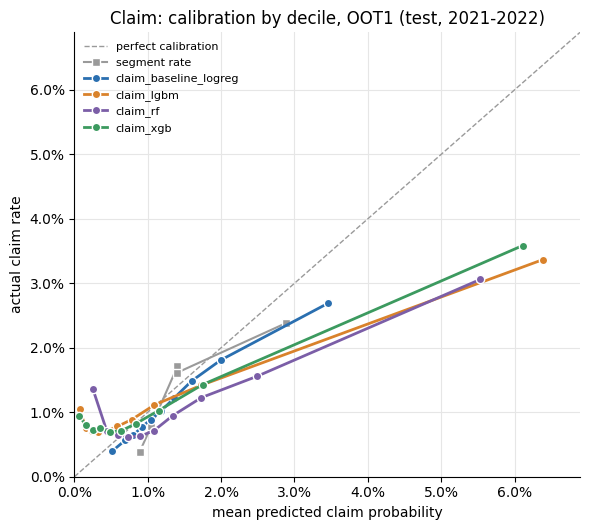

,actual,expected: base rate,expected: segment rate,expected: claim_baseline_logreg,expected: claim_lgbm,expected: claim_rf,expected: claim_xgb
period_year,,,,,,,
2021,"37,422","48,833","48,910","45,362","39,077","53,125","43,798"
2022,"46,181","45,848","46,429","53,330","46,731","56,627","42,020"
all,"83,603","94,680","95,339","98,692","85,808","109,752","85,818"


,rows,events,predicted,actual,actual_to_predicted
p_claim_xgb,,,,,
10,"727,572","26,085",6.111%,3.585%,0.59
9,"727,572","10,400",1.749%,1.429%,0.82
8,"727,571","7,467",1.148%,1.026%,0.89
7,"727,572","6,001",0.840%,0.825%,0.98
6,"727,571","5,177",0.635%,0.712%,1.12
5,"727,572","5,075",0.481%,0.698%,1.45
4,"727,572","5,461",0.355%,0.751%,2.12
3,"727,571","5,310",0.249%,0.730%,2.93
2,"727,572","5,803",0.158%,0.798%,5.05


,model,a_to_e,ece,ece_pct_of_rate,intercept_a,slope_b
0,segment rate,0.877,0.00387,33.7%,+0.974,1.260
1,claim_baseline_logreg,0.847,0.00207,18.0%,-0.221,0.983
2,claim_lgbm,0.974,0.00635,55.2%,-2.213,0.455
3,claim_rf,0.762,0.00651,56.6%,-2.367,0.473
4,claim_xgb,0.974,0.00566,49.3%,-2.126,0.477


In [22]:
# Step 1.2 Claim: calibration by decile, ECE, intercept and slope, and expected vs actual per year
calib_claim, deciles_claim = ev.calibration_summary(pred["claim"], COLS["claim"], seed=SEED)
fig, ax = plt.subplots(figsize=(6, 5.4))
ev.plot_calibration(ax, deciles_claim, f"Claim: calibration by decile, {EVAL_NAME}", "claim")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_claim_calibration.png", dpi=150)
plt.show()

p = pred["claim"]
expected_claim = p.groupby("period_year").agg(actual=("y", "sum"), **{f"expected: {n}": (c, "sum") for n, c in COLS["claim"].items()})
expected_claim.loc["all"] = expected_claim.sum()
display(expected_claim.style.format("{:,.0f}"))
display(deciles_claim[PRIMARY["claim"]].sort_index(ascending=False).style.format(
    {"rows": "{:,}", "events": "{:,}", "predicted": "{:.3%}", "actual": "{:.3%}", "actual_to_predicted": "{:.2f}"}))
calib_claim.style.format({"a_to_e": "{:.3f}", "ece": "{:.5f}", "ece_pct_of_rate": "{:.1%}", "intercept_a": "{:+.3f}", "slope_b": "{:.3f}"})

#### 1.3 Calibration by segment
A model can be right on average and wrong for whole groups. For each segment we show the actual rate, each model's **A/E** and the log-loss skill. The chart shows the primary model's A/E with a 95% interval, $\text{A/E} \times \big(1 \pm 1.96/\sqrt{\text{actual claims}}\big)$; the shaded band (0.8–1.2) is the "watch" band of the monitoring rules.

**Storm during the term** uses the strongest IBTrACS wind at the property during the term (an outcome-period measure, used only here). We expect the model to **under-predict where a storm hit and over-predict where none did**, since no model can know at the start where the next storm will land. What matters is that the two balance out over the portfolio.

In [23]:
# Step 1.3 (setup) The segments used for both targets
def top_states(frame, n=10):
    keep = frame["state"].value_counts().index[:n]
    return frame["state"].where(frame["state"].isin(keep), "other states")

SEGMENTS = {"state (largest 10)": top_states, "flood zone group": lambda f: f["zone_group"],
            "new business": lambda f: f["new_business"].map({1: "new business", 0: "renewal"}),
            "mandatory purchase": lambda f: f["mandatory_purchase"].map({1: "mandatory", 0: "voluntary"}),
            "storm during the term": lambda f: f["storm_in_term"]}

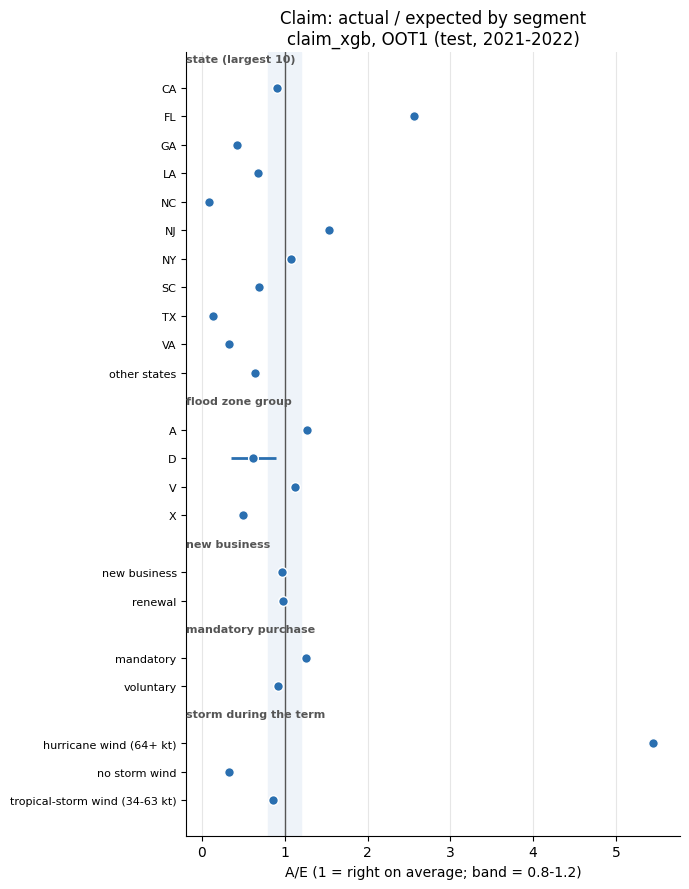

state (largest 10)


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,CA,base rate,"340,160","1,808",0.532%,0.408,+0.00%
1,CA,segment rate,"340,160","1,808",0.532%,0.431,+2.66%
2,CA,claim_baseline_logreg,"340,160","1,808",0.532%,0.667,+9.83%
3,CA,claim_lgbm,"340,160","1,808",0.532%,0.843,+12.77%
4,CA,claim_rf,"340,160","1,808",0.532%,0.743,+12.84%
5,CA,claim_xgb,"340,160","1,808",0.532%,0.906,+12.72%
6,FL,base rate,"2,022,563","45,858",2.267%,1.742,+0.00%
7,FL,segment rate,"2,022,563","45,858",2.267%,1.795,+2.62%
8,FL,claim_baseline_logreg,"2,022,563","45,858",2.267%,1.730,+4.61%
9,FL,claim_lgbm,"2,022,563","45,858",2.267%,2.308,-16.22%


flood zone group


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,A,base rate,"3,596,813","64,718",1.799%,1.383,+0.00%
1,A,segment rate,"3,596,813","64,718",1.799%,1.140,+0.92%
2,A,claim_baseline_logreg,"3,596,813","64,718",1.799%,1.185,+2.36%
3,A,claim_lgbm,"3,596,813","64,718",1.799%,1.246,-6.79%
4,A,claim_rf,"3,596,813","64,718",1.799%,0.998,-3.59%
5,A,claim_xgb,"3,596,813","64,718",1.799%,1.266,-5.44%
6,D,base rate,"2,913",20,0.687%,0.528,+0.00%
7,D,segment rate,"2,913",20,0.687%,0.599,+4.88%
8,D,claim_baseline_logreg,"2,913",20,0.687%,0.380,-8.79%
9,D,claim_lgbm,"2,913",20,0.687%,0.542,+4.40%


new business


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,new business,base rate,"1,348,232","16,950",1.257%,0.966,+0.00%
1,new business,segment rate,"1,348,232","16,950",1.257%,1.063,+1.98%
2,new business,claim_baseline_logreg,"1,348,232","16,950",1.257%,0.891,+1.57%
3,new business,claim_lgbm,"1,348,232","16,950",1.257%,0.983,-3.44%
4,new business,claim_rf,"1,348,232","16,950",1.257%,0.834,-1.41%
5,new business,claim_xgb,"1,348,232","16,950",1.257%,0.973,-3.31%
6,renewal,base rate,"5,927,485","66,653",1.124%,0.864,+0.00%
7,renewal,segment rate,"5,927,485","66,653",1.124%,0.840,+2.60%
8,renewal,claim_baseline_logreg,"5,927,485","66,653",1.124%,0.837,+3.02%
9,renewal,claim_lgbm,"5,927,485","66,653",1.124%,0.972,-1.92%


mandatory purchase


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,mandatory,base rate,"1,120,514","18,325",1.635%,1.257,+0.00%
1,mandatory,segment rate,"1,120,514","18,325",1.635%,1.139,+1.11%
2,mandatory,claim_baseline_logreg,"1,120,514","18,325",1.635%,1.127,+2.12%
3,mandatory,claim_lgbm,"1,120,514","18,325",1.635%,1.260,-6.33%
4,mandatory,claim_rf,"1,120,514","18,325",1.635%,1.008,-3.56%
5,mandatory,claim_xgb,"1,120,514","18,325",1.635%,1.263,-4.64%
6,voluntary,base rate,"6,155,203","65,278",1.061%,0.815,+0.00%
7,voluntary,segment rate,"6,155,203","65,278",1.061%,0.824,+2.83%
8,voluntary,claim_baseline_logreg,"6,155,203","65,278",1.061%,0.792,+2.89%
9,voluntary,claim_lgbm,"6,155,203","65,278",1.061%,0.916,-1.16%


storm during the term


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,hurricane wind (64+ kt),base rate,"484,024","40,942",8.459%,6.500,+0.00%
1,hurricane wind (64+ kt),segment rate,"484,024","40,942",8.459%,6.552,+2.89%
2,hurricane wind (64+ kt),claim_baseline_logreg,"484,024","40,942",8.459%,6.084,+4.46%
3,hurricane wind (64+ kt),claim_lgbm,"484,024","40,942",8.459%,6.125,-15.11%
4,hurricane wind (64+ kt),claim_rf,"484,024","40,942",8.459%,5.153,-6.89%
5,hurricane wind (64+ kt),claim_xgb,"484,024","40,942",8.459%,5.449,-13.15%
6,no storm wind,base rate,"3,997,633","15,004",0.375%,0.288,+0.00%
7,no storm wind,segment rate,"3,997,633","15,004",0.375%,0.284,+1.06%
8,no storm wind,claim_baseline_logreg,"3,997,633","15,004",0.375%,0.267,-2.00%
9,no storm wind,claim_lgbm,"3,997,633","15,004",0.375%,0.307,+2.10%


In [24]:
# Step 1.3 Claim: A/E and skill by segment, for every model; chart for the primary model
seg_claim = {label: ev.segment_table(pred["claim"], COLS["claim"], key(pred["claim"])) for label, key in SEGMENTS.items()}
fig, ax = plt.subplots(figsize=(7, 9))
ev.plot_ae_by_segment(ax, seg_claim, PRIMARY["claim"], f"Claim: actual / expected by segment\n{PRIMARY['claim']}, {EVAL_NAME}")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_claim_segments.png", dpi=150)
plt.show()
for label, t in seg_claim.items():
    print(label)
    display(t[["segment", "model", "rows", "events", "actual_rate", "a_to_e", "log_loss_skill"]].style.format(
        {"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "a_to_e": "{:.3f}", "log_loss_skill": "{:+.2%}"}))

#### 1.4 Stability over time
We score a random sample of every year from 2014 and follow the A/E and the log-loss skill: **in-sample** (2014–2020), **OOT1** (2021–2022) and **OOT2** (2023 – Aug 2024, final run only).

The claim A/E swings with the storms even for a good model. What we look for is a **trend** (A/E drifting from 1) or skill falling below 0 out of time.

scored 9 years in 1.9 min


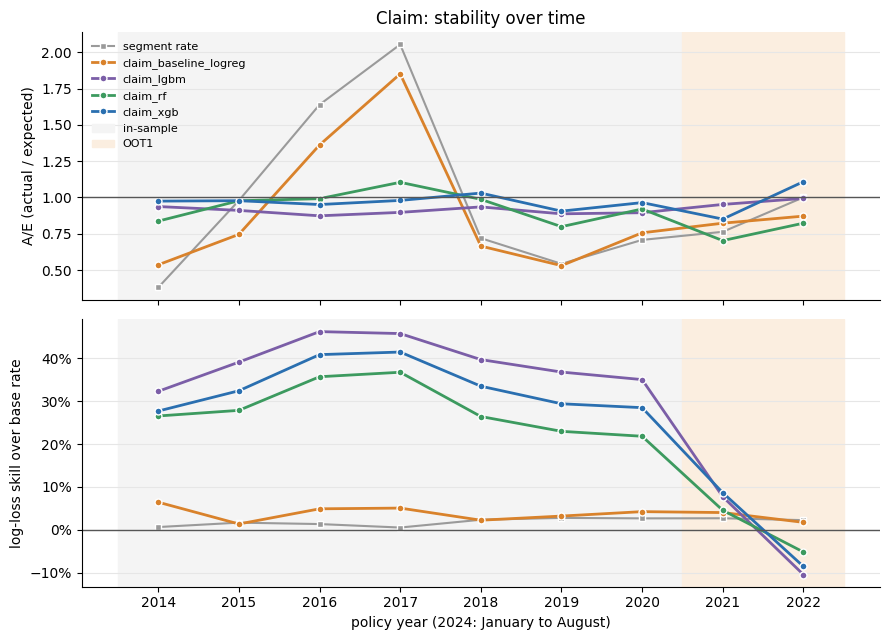

a_to_e                                                      \
model          base rate claim_baseline_logreg claim_lgbm claim_rf claim_xgb   
year period                                                                    
2014 in-sample     0.381                 0.536      0.937    0.837     0.975   
2015 in-sample     0.978                 0.746      0.911    0.977     0.978   
2016 in-sample     1.631                 1.361      0.873    0.991     0.951   
2017 in-sample     2.048                 1.851      0.897    1.104     0.979   
2018 in-sample     0.725                 0.665      0.935    0.987      1.03   
2019 in-sample     0.545                  0.53      0.887    0.799     0.906   
2020 in-sample     0.706                 0.756      0.895     0.92     0.964   
2021 OOT1          0.765                 0.823      0.952    0.703     0.851   
2022 OOT1          1.011                 0.871      0.993    0.823     1.108   

                            log_loss_skill                                   \
model          segment rate      base rate claim_baseline_logreg claim_lgbm   
year period                                                                   
2014 in-sample         0.38              0                 0.064      0.323   
2015 in-sample        0.979              0                 0.014      0.391   
2016 in-sample        1.639              0                 0.049      0.462   
2017 in-sample        2.053              0                 0.051      0.457   
2018 in-sample        0.719              0                 0.022      0.397   
2019 in-sample        0.543              0                 0.032      0.368   
2020 in-sample        0.707              0                 0.042       0.35   
2021 OOT1             0.763              0                  0.04      0.077   
2022 OOT1                 1              0                 0.017     -0.104   

                                                
model          claim_rf claim_xgb segment rate  
year period                                     
2014 in-sample    0.265     0.277        0.006  
2015 in-sample    0.278     0.324        0.017  
2016 in-sample    0.357     0.408        0.013  
2017 in-sample    0.367     0.414        0.005  
2018 in-sample    0.264     0.335        0.023  
2019 in-sample     0.23     0.294        0.028  
2020 in-sample    0.218     0.285        0.027  
2021 OOT1         0.045     0.086        0.027  
2022 OOT1        -0.052    -0.085        0.023

In [25]:
# Step 1.4 Claim: A/E and log-loss skill per year, 2014 to LAST_YEAR, on a sample of each year
t0 = time.time()
stability_claim = ev.stability_by_year(con, "claim", registry["claim"], base_rate["claim"], KINDS,
                                        range(2014, LAST_YEAR + 1), STABILITY_ROWS, seed=SEED)
print(f"scored {stability_claim['year'].nunique()} years in {(time.time() - t0) / 60:.1f} min")
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
ev.plot_by_year(axes, stability_claim, COLS["claim"], f"Claim: stability over time")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_claim_stability.png", dpi=150)
plt.show()
stability_claim.pivot_table(index=["year", "period"], columns="model", values=["a_to_e", "log_loss_skill"]).round(3)

#### 1.5 Simulated monitoring
We treat each quarter after the development years as if it had just arrived in production. The **reference** is a sample of the **same calendar quarter** in 2014–2020, because several features are seasonal (start month, rain in the last 90 days, days since the last storm).

**Population stability index**, with $r_b$ the reference share and $c_b$ the current share in bin $b$ (10 quantile bins for numbers; the 15 largest categories plus "other"; missing as its own bin):
$$\text{PSI} = \sum_{b}\big(c_b - r_b\big)\,\ln\frac{c_b}{r_b}$$

| Check | OK | Watch | Action |
|---|---|---|---|
| Feature PSI | < 0.10 | 0.10 – 0.25 | > 0.25: review the feature's data and definition |
| Score PSI (the predicted probability) | < 0.10 | 0.10 – 0.25 | > 0.25: the mix of risks has changed; review with A/E |
| A/E per quarter | 0.9 – 1.1 | 0.8 – 0.9 or 1.1 – 1.2 | outside 0.8 – 1.2 for **two quarters in a row**: recalibrate |
| Log-loss skill per quarter | > 0 | — | below 0 for **two quarters in a row**: retrain |

A large feature PSI is not an error by itself. **Risk Rating 2.0** (from October 2021) changed premiums, deductible options and rate-type codes, so the price and deductible features cross 0.25 in every quarter after 2021, and time-based features drift as the years pass. Drift matters when the A/E moves too.

**For claims**, one storm quarter pushes the A/E far above 1 with nothing wrong in the model, so we read the claim A/E over **four rolling quarters** and act only on a persistent trend.

8 quarters in 2.1 min


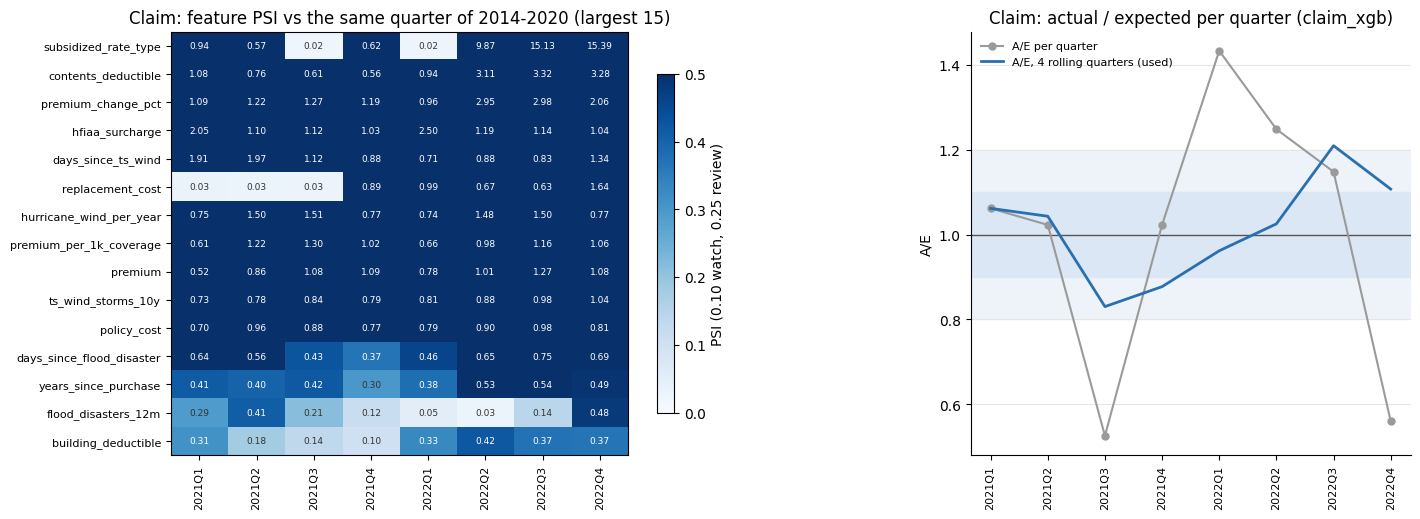

,quarter,score_psi,max_feature_psi,features_over_0.25,a_to_e,a_to_e_used,log_loss_skill,status,action
0,2021Q1,0.101,2.047,15,1.062,1.062,+26.05%,feature PSI > 0.25; score PSI watch,
1,2021Q2,0.107,1.966,14,1.023,1.043,+23.44%,feature PSI > 0.25; score PSI watch,
2,2021Q3,0.123,1.508,12,0.526,0.830,+10.10%,feature PSI > 0.25; score PSI watch; A/E watch,
3,2021Q4,0.146,1.194,14,1.023,0.877,-24.03%,feature PSI > 0.25; score PSI watch; A/E watch; skill < 0,
4,2022Q1,0.173,2.497,14,1.433,0.962,-24.45%,feature PSI > 0.25; score PSI watch; skill < 0,retrain
5,2022Q2,0.356,9.871,16,1.248,1.025,-15.00%,feature PSI > 0.25; score PSI > 0.25; skill < 0,retrain
6,2022Q3,0.353,15.126,16,1.148,1.209,+0.24%,feature PSI > 0.25; score PSI > 0.25; A/E outside 0.8-1.2,
7,2022Q4,0.274,15.393,19,0.560,1.107,+4.79%,feature PSI > 0.25; score PSI > 0.25; A/E watch,


In [26]:
# Step 1.5 Claim: feature PSI, score PSI and A/E per quarter, and the alert rules
t0 = time.time()
monitor_claim, psi_claim = ev.monitor_quarters(con, "claim", registry["claim"], base_rate["claim"], KINDS, PRIMARY["claim"],
                                                 QUARTERS, REFERENCE_ROWS, QUARTER_ROWS, seed=SEED)
alerts_claim = ev.apply_alert_rules(monitor_claim, rolling_quarters=4)
print(f"{len(QUARTERS)} quarters in {(time.time() - t0) / 60:.1f} min")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.45})
im = ev.plot_psi_heatmap(ax1, psi_claim, f"Claim: feature PSI vs the same quarter of 2014-2020 (largest 15)")
fig.colorbar(im, ax=ax1, shrink=0.8, label="PSI (0.10 watch, 0.25 review)")
x = np.arange(len(alerts_claim))
ax2.axhspan(0.8, 1.2, color="#eef3f9", zorder=0); ax2.axhspan(0.9, 1.1, color="#dbe7f4", zorder=0)
ax2.axhline(1, color="#555555", linewidth=1)
ax2.plot(x, alerts_claim["a_to_e"], color=ev.GREY, linewidth=1.5, marker="o", markersize=5, label="A/E per quarter")
if 4:
    ax2.plot(x, alerts_claim["a_to_e_used"], color="#2a6fb0", linewidth=2, label="A/E, 4 rolling quarters (used)")
ax2.set_xticks(x, alerts_claim["quarter"], rotation=90, fontsize=8)
ax2.set(title=f"Claim: actual / expected per quarter ({PRIMARY['claim']})", ylabel="A/E")
ax2.legend(frameon=False, fontsize=8)
ev.style_axes(ax2, grid="y")
plt.savefig(REPORTS / f"fig_{OUT}_claim_monitoring.png", dpi=150, bbox_inches="tight")
plt.show()
alerts_claim[["quarter", "score_psi", "max_feature_psi", "features_over_0.25", "a_to_e", "a_to_e_used", "log_loss_skill",
               "status", "action"]].style.format({"score_psi": "{:.3f}", "max_feature_psi": "{:.3f}", "a_to_e": "{:.3f}",
                                                   "a_to_e_used": "{:.3f}", "log_loss_skill": "{:+.2%}"})

### Section 2. Lapse model

#### 2.1 Probability check
The same measures as Step 1.1.

In [27]:
# Step 2.1 Lapse: log loss, Brier, skill and A/E, overall and per year
p = pred["lapse"]
prob_lapse = ev.probability_table([(EVAL_NAME, p), *[(str(y), g) for y, g in p.groupby("period_year")]], COLS["lapse"])
prob_lapse.style.format({"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "predicted_rate": "{:.3%}",
                          "a_to_e": "{:.3f}", "log_loss": "{:.5f}", "brier": "{:.6f}", "log_loss_skill": "{:+.2%}",
                          "brier_skill": "{:+.2%}"})

,scope,model,rows,events,actual_rate,predicted_rate,a_to_e,log_loss,brier,log_loss_skill,brier_skill
0,"OOT1 (test, 2021-2022)",base rate,"7,105,637","854,084",12.020%,13.839%,0.869,0.36876,0.106082,+0.00%,+0.00%
1,"OOT1 (test, 2021-2022)",segment rate,"7,105,637","854,084",12.020%,13.394%,0.897,0.35819,0.103381,+2.87%,+2.55%
2,"OOT1 (test, 2021-2022)",lapse_baseline_logreg,"7,105,637","854,084",12.020%,11.856%,1.014,0.35128,0.102190,+4.74%,+3.67%
3,"OOT1 (test, 2021-2022)",lapse_rf,"7,105,637","854,084",12.020%,12.054%,0.997,0.34381,0.100462,+6.77%,+5.30%
4,"OOT1 (test, 2021-2022)",lapse_xgb,"7,105,637","854,084",12.020%,11.201%,1.073,0.34653,0.101071,+6.03%,+4.72%
5,2021,base rate,"3,648,441","465,877",12.769%,13.839%,0.923,0.38247,0.111501,+0.00%,+0.00%
6,2021,segment rate,"3,648,441","465,877",12.769%,13.102%,0.975,0.37728,0.110135,+1.36%,+1.23%
7,2021,lapse_baseline_logreg,"3,648,441","465,877",12.769%,11.665%,1.095,0.36507,0.107337,+4.55%,+3.73%
8,2021,lapse_rf,"3,648,441","465,877",12.769%,11.536%,1.107,0.35077,0.104113,+8.29%,+6.63%
9,2021,lapse_xgb,"3,648,441","465,877",12.769%,11.040%,1.157,0.35027,0.104172,+8.42%,+6.57%


#### 2.2 Calibration
As in Step 1.2: deciles, ECE, intercept and slope, and expected vs actual lapses.

/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warning

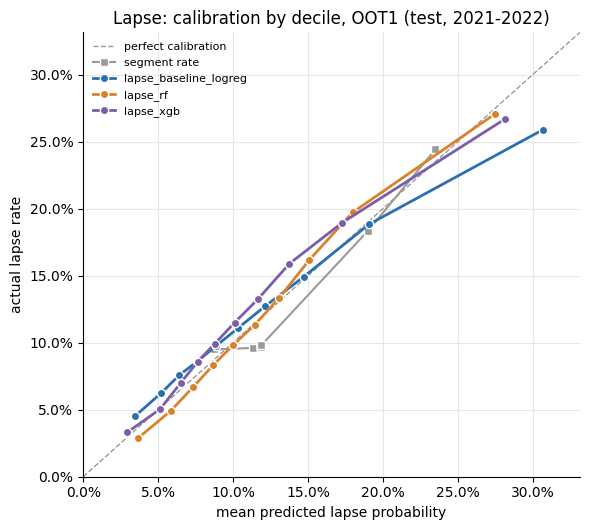

,actual,expected: base rate,expected: segment rate,expected: lapse_baseline_logreg,expected: lapse_rf,expected: lapse_xgb
period_year,,,,,,
2021,"465,877","504,917","478,033","425,582","420,870","402,793"
2022,"388,207","478,451","473,704","416,892","435,621","393,105"
all,"854,084","983,368","951,737","842,475","856,491","795,898"


,rows,events,predicted,actual,actual_to_predicted
p_lapse_rf,,,,,
10,"710,564","192,212",27.456%,27.051%,0.99
9,"710,564","140,101",17.983%,19.717%,1.10
8,"710,563","115,045",15.104%,16.191%,1.07
7,"710,564","94,770",13.077%,13.337%,1.02
6,"710,563","80,407",11.438%,11.316%,0.99
5,"710,564","69,893",10.016%,9.836%,0.98
4,"710,564","59,104",8.671%,8.318%,0.96
3,"710,563","47,424",7.324%,6.674%,0.91
2,"710,564","34,848",5.833%,4.904%,0.84


,model,a_to_e,ece,ece_pct_of_rate,intercept_a,slope_b
0,segment rate,0.897,0.01705,14.2%,+0.250,1.207
1,lapse_baseline_logreg,1.014,0.01172,9.7%,-0.374,0.790
2,lapse_rf,0.997,0.00650,5.4%,+0.132,1.072
3,lapse_xgb,1.073,0.01129,9.4%,-0.067,0.921


In [28]:
# Step 2.2 Lapse: calibration by decile, ECE, intercept and slope, and expected vs actual per year
calib_lapse, deciles_lapse = ev.calibration_summary(pred["lapse"], COLS["lapse"], seed=SEED)
fig, ax = plt.subplots(figsize=(6, 5.4))
ev.plot_calibration(ax, deciles_lapse, f"Lapse: calibration by decile, {EVAL_NAME}", "lapse")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_calibration.png", dpi=150)
plt.show()

p = pred["lapse"]
expected_lapse = p.groupby("period_year").agg(actual=("y", "sum"), **{f"expected: {n}": (c, "sum") for n, c in COLS["lapse"].items()})
expected_lapse.loc["all"] = expected_lapse.sum()
display(expected_lapse.style.format("{:,.0f}"))
display(deciles_lapse[PRIMARY["lapse"]].sort_index(ascending=False).style.format(
    {"rows": "{:,}", "events": "{:,}", "predicted": "{:.3%}", "actual": "{:.3%}", "actual_to_predicted": "{:.2f}"}))
calib_lapse.style.format({"a_to_e": "{:.3f}", "ece": "{:.5f}", "ece_pct_of_rate": "{:.1%}", "intercept_a": "{:+.3f}", "slope_b": "{:.3f}"})

#### 2.3 Calibration by segment
As in Step 1.3. For lapse, the storm segment shows whether policyholders hit by a storm renewed more or less than expected.

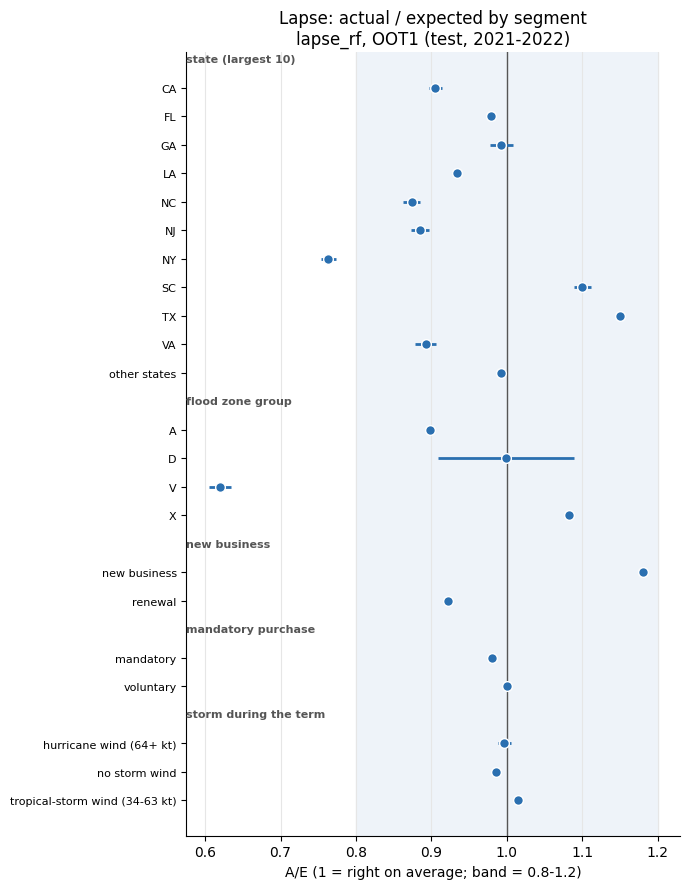

state (largest 10)


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,CA,base rate,"334,492","38,372",11.472%,0.829,+0.00%
1,CA,segment rate,"334,492","38,372",11.472%,0.878,+1.74%
2,CA,lapse_baseline_logreg,"334,492","38,372",11.472%,0.921,+2.86%
3,CA,lapse_rf,"334,492","38,372",11.472%,0.905,+5.06%
4,CA,lapse_xgb,"334,492","38,372",11.472%,0.969,+3.67%
5,FL,base rate,"1,964,173","216,393",11.017%,0.796,+0.00%
6,FL,segment rate,"1,964,173","216,393",11.017%,0.827,+2.35%
7,FL,lapse_baseline_logreg,"1,964,173","216,393",11.017%,0.949,+3.31%
8,FL,lapse_rf,"1,964,173","216,393",11.017%,0.979,+4.99%
9,FL,lapse_xgb,"1,964,173","216,393",11.017%,1.027,+4.12%


flood zone group


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,A,base rate,"3,516,657","329,893",9.381%,0.678,+0.00%
1,A,segment rate,"3,516,657","329,893",9.381%,0.726,+2.39%
2,A,lapse_baseline_logreg,"3,516,657","329,893",9.381%,0.881,+6.06%
3,A,lapse_rf,"3,516,657","329,893",9.381%,0.898,+8.77%
4,A,lapse_xgb,"3,516,657","329,893",9.381%,0.959,+8.34%
5,D,base rate,"2,846",466,16.374%,1.183,+0.00%
6,D,segment rate,"2,846",466,16.374%,1.114,+2.79%
7,D,lapse_baseline_logreg,"2,846",466,16.374%,0.874,+4.93%
8,D,lapse_rf,"2,846",466,16.374%,0.999,+7.07%
9,D,lapse_xgb,"2,846",466,16.374%,0.835,+5.13%


new business


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,new business,base rate,"1,313,546","293,185",22.320%,1.613,+0.00%
1,new business,segment rate,"1,313,546","293,185",22.320%,1.013,+5.59%
2,new business,lapse_baseline_logreg,"1,313,546","293,185",22.320%,1.021,+5.75%
3,new business,lapse_rf,"1,313,546","293,185",22.320%,1.181,+6.67%
4,new business,lapse_xgb,"1,313,546","293,185",22.320%,1.171,+3.57%
5,renewal,base rate,"5,792,091","560,899",9.684%,0.700,+0.00%
6,renewal,segment rate,"5,792,091","560,899",9.684%,0.847,+1.81%
7,renewal,lapse_baseline_logreg,"5,792,091","560,899",9.684%,1.010,+4.35%
8,renewal,lapse_rf,"5,792,091","560,899",9.684%,0.922,+6.80%
9,renewal,lapse_xgb,"5,792,091","560,899",9.684%,1.028,+6.98%


mandatory purchase


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,mandatory,base rate,"1,091,753","114,718",10.508%,0.759,+0.00%
1,mandatory,segment rate,"1,091,753","114,718",10.508%,1.004,+1.81%
2,mandatory,lapse_baseline_logreg,"1,091,753","114,718",10.508%,1.164,+4.92%
3,mandatory,lapse_rf,"1,091,753","114,718",10.508%,0.980,+8.86%
4,mandatory,lapse_xgb,"1,091,753","114,718",10.508%,1.117,+8.77%
5,voluntary,base rate,"6,013,884","739,366",12.294%,0.888,+0.00%
6,voluntary,segment rate,"6,013,884","739,366",12.294%,0.883,+3.04%
7,voluntary,lapse_baseline_logreg,"6,013,884","739,366",12.294%,0.994,+4.71%
8,voluntary,lapse_rf,"6,013,884","739,366",12.294%,1.000,+6.42%
9,voluntary,lapse_xgb,"6,013,884","739,366",12.294%,1.067,+5.58%


storm during the term


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,hurricane wind (64+ kt),base rate,"477,577","55,650",11.653%,0.842,+0.00%
1,hurricane wind (64+ kt),segment rate,"477,577","55,650",11.653%,0.865,+3.47%
2,hurricane wind (64+ kt),lapse_baseline_logreg,"477,577","55,650",11.653%,0.941,+3.86%
3,hurricane wind (64+ kt),lapse_rf,"477,577","55,650",11.653%,0.997,+5.42%
4,hurricane wind (64+ kt),lapse_xgb,"477,577","55,650",11.653%,1.085,+3.66%
5,no storm wind,base rate,"3,880,413","480,490",12.382%,0.895,+0.00%
6,no storm wind,segment rate,"3,880,413","480,490",12.382%,0.921,+3.00%
7,no storm wind,lapse_baseline_logreg,"3,880,413","480,490",12.382%,1.021,+4.58%
8,no storm wind,lapse_rf,"3,880,413","480,490",12.382%,0.986,+6.36%
9,no storm wind,lapse_xgb,"3,880,413","480,490",12.382%,1.073,+5.53%


In [29]:
# Step 2.3 Lapse: A/E and skill by segment, for every model; chart for the primary model
seg_lapse = {label: ev.segment_table(pred["lapse"], COLS["lapse"], key(pred["lapse"])) for label, key in SEGMENTS.items()}
fig, ax = plt.subplots(figsize=(7, 9))
ev.plot_ae_by_segment(ax, seg_lapse, PRIMARY["lapse"], f"Lapse: actual / expected by segment\n{PRIMARY['lapse']}, {EVAL_NAME}")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_segments.png", dpi=150)
plt.show()
for label, t in seg_lapse.items():
    print(label)
    display(t[["segment", "model", "rows", "events", "actual_rate", "a_to_e", "log_loss_skill"]].style.format(
        {"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "a_to_e": "{:.3f}", "log_loss_skill": "{:+.2%}"}))

#### 2.4 Stability over time
As in Step 1.4. Lapse moves slowly, so a trend is easier to see than for claims.

/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/sr

scored 9 years in 1.8 min


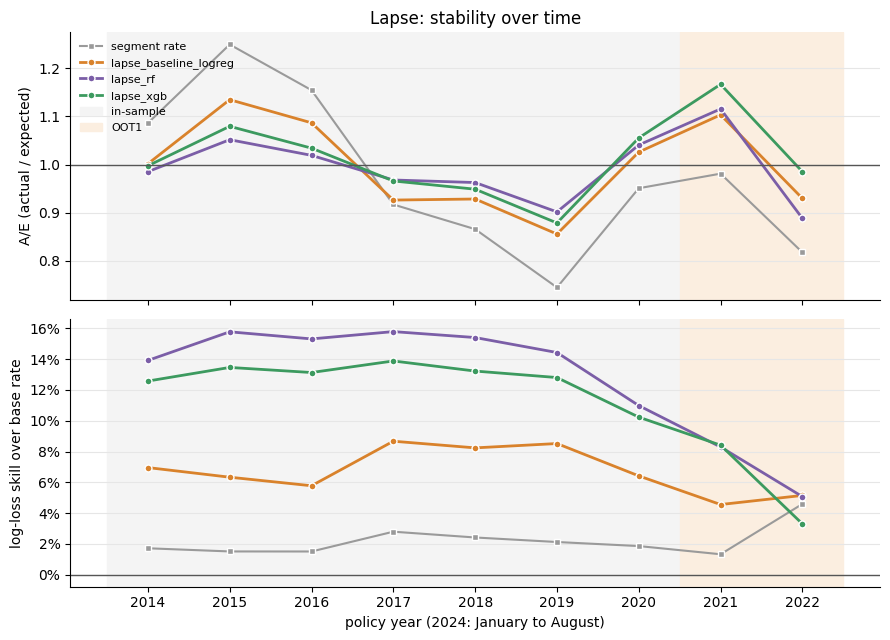

a_to_e                                           \
model          base rate lapse_baseline_logreg lapse_rf lapse_xgb   
year period                                                         
2014 in-sample     1.152                 1.001    0.985     0.997   
2015 in-sample     1.302                 1.135    1.052     1.079   
2016 in-sample     1.113                 1.087    1.019     1.034   
2017 in-sample     0.938                 0.926    0.968     0.966   
2018 in-sample     0.877                 0.928    0.963     0.949   
2019 in-sample     0.733                 0.856    0.902     0.879   
2020 in-sample     0.862                 1.026    1.041     1.055   
2021 OOT1          0.929                 1.103    1.115     1.167   
2022 OOT1          0.809                  0.93    0.888     0.985   

                            log_loss_skill                                 \
model          segment rate      base rate lapse_baseline_logreg lapse_rf   
year period                                                                 
2014 in-sample        1.086              0                  0.07    0.139   
2015 in-sample        1.249              0                 0.063    0.158   
2016 in-sample        1.155              0                 0.058    0.153   
2017 in-sample        0.917              0                 0.087    0.158   
2018 in-sample        0.866              0                 0.082    0.154   
2019 in-sample        0.745              0                 0.085    0.144   
2020 in-sample        0.951              0                 0.064     0.11   
2021 OOT1             0.981              0                 0.046    0.083   
2022 OOT1             0.817              0                 0.051    0.051   

                                       
model          lapse_xgb segment rate  
year period                            
2014 in-sample     0.126        0.017  
2015 in-sample     0.135        0.015  
2016 in-sample     0.131        0.015  
2017 in-sample     0.139        0.028  
2018 in-sample     0.132        0.024  
2019 in-sample     0.128        0.021  
2020 in-sample     0.102        0.019  
2021 OOT1          0.084        0.013  
2022 OOT1          0.033        0.046

In [30]:
# Step 2.4 Lapse: A/E and log-loss skill per year, 2014 to LAST_YEAR, on a sample of each year
t0 = time.time()
stability_lapse = ev.stability_by_year(con, "lapse", registry["lapse"], base_rate["lapse"], KINDS,
                                        range(2014, LAST_YEAR + 1), STABILITY_ROWS, seed=SEED)
print(f"scored {stability_lapse['year'].nunique()} years in {(time.time() - t0) / 60:.1f} min")
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
ev.plot_by_year(axes, stability_lapse, COLS["lapse"], f"Lapse: stability over time")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_stability.png", dpi=150)
plt.show()
stability_lapse.pivot_table(index=["year", "period"], columns="model", values=["a_to_e", "log_loss_skill"]).round(3)

#### 2.5 Cohort survival analysis: retention of new business
Steps 2.1–2.4 judge the lapse model one policy-year at a time. An insurer also needs to know **how long a new policy stays**: of the policies sold in a year, how many are still in force after 1, 2, 3, … years? That is a **survival** (retention) curve.

**Cohort:** all policies that start as **new business** (tenure under one year, no earlier policy-year on the same key) in the same year. We follow a random sample of 30,000 policies per cohort; year $k$ is the $k$-th policy-year since the sale.

**Life table.** In each year $k$, a policy at risk either lapses (cancelled during the term or not renewed), renews into year $k+1$, or is **censored**: we stop seeing it without a lapse, because the data end or a later policy-year left the modeling population. Censored policies are not counted as lapses.
$$h_k = \frac{\text{lapsed in year } k}{\text{at risk at the start of year } k} \qquad S(k) = \prod_{j=1}^{k}\big(1 - h_j\big)$$
$h_k$ is the **lapse hazard** and $S(k)$ the **survival**, the share still in force after $k$ years (Kaplan–Meier for yearly steps).

**What the model predicts.** Our lapse model predicts per policy-year, so it is a **discrete-time hazard model**: $p_{ik}$ is the probability that policy $i$ lapses in year $k$, given it is still in force. Averaging over the same policies at risk gives the model's hazard and survival:
$$\hat h_k = \frac{1}{n_k}\sum_{i \,\in\, \text{at risk at } k} p_{ik} \qquad \hat S(k) = \prod_{j=1}^{k}\big(1 - \hat h_j\big)$$
A gap between $S(k)$ and $\hat S(k)$ that **grows with $k$** means the yearly errors add up, which matters for premium forecasts several years ahead.

**Limits:** only cohorts sold from 2014 (left truncation); later cohorts have shorter curves (a year is shown while at least 500 policies are at risk); only the first spell, up to the first lapse; nothing after 2022 in the dry run.

/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/sr

270,000 policies in 9 cohorts, 807,704 policy-years (0.5 min)


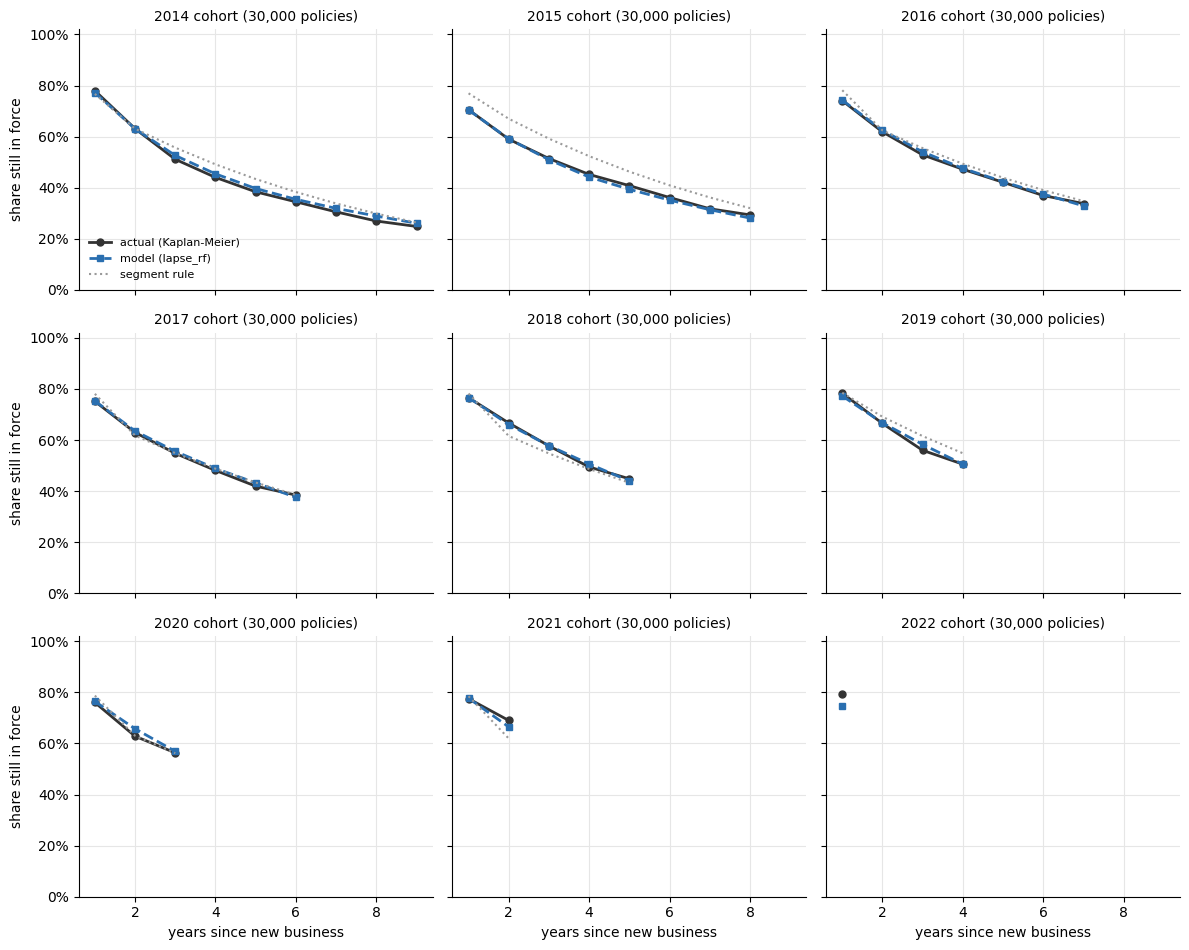

,at_risk,lapsed,cancelled,not_renewed,censored,hazard_actual,hazard_model,survival_actual,survival_model,survival_segment rule
year_k,,,,,,,,,,
1,"270,000","64,293",672,"64,284","29,269",23.81%,24.43%,76.2%,75.6%,77.8%
2,"176,438","27,449",313,"27,443","24,638",15.56%,15.23%,64.3%,64.1%,63.6%
3,"124,351","17,600",200,"17,594","19,087",14.15%,13.56%,55.2%,55.4%,56.5%
4,"87,664","10,634",139,"10,630","15,906",12.13%,12.78%,48.5%,48.3%,50.1%
5,"61,124","6,757",91,"6,754","13,195",11.05%,11.82%,43.2%,42.6%,44.5%
6,"41,172","4,346",104,"4,343","10,651",10.56%,11.57%,38.6%,37.7%,39.4%
7,"26,175","2,791",58,"2,789","8,710",10.66%,10.99%,34.5%,33.5%,34.9%
8,"14,674","1,403",21,"1,403","7,165",9.56%,9.94%,31.2%,30.2%,30.8%
9,"6,106",481,16,481,"5,625",7.88%,9.78%,28.7%,27.2%,27.2%


,cohort,year_k,at_risk,survival_actual,survival_model,survival_segment rule,gap_model_pp,gap_segment_pp
0,2014,1,"30,000",78.0%,77.2%,76.7%,-0.8,-1.3
1,2014,2,"22,653",63.1%,63.1%,63.1%,-0.0,-0.0
2,2014,3,"17,745",51.1%,52.6%,55.7%,+1.5,+4.6
4,2014,5,"11,457",38.4%,39.7%,43.4%,+1.3,+5.0
9,2015,1,"30,000",70.5%,70.4%,77.0%,-0.1,+6.4
10,2015,2,"20,587",59.0%,59.1%,67.0%,+0.1,+8.0
11,2015,3,"16,647",51.4%,51.0%,59.2%,-0.5,+7.8
13,2015,5,"11,925",40.8%,39.4%,46.3%,-1.4,+5.5
17,2016,1,"30,000",74.1%,74.3%,78.2%,+0.2,+4.1
18,2016,2,"21,534",61.8%,62.5%,62.4%,+0.6,+0.6


In [31]:
# Step 2.5 New-business cohorts: actual vs predicted lapse hazard and survival, year by year
MIN_AT_RISK = 500
t0 = time.time()
cohort_years = ev.build_cohort_keys(con, LAST_YEAR, COHORT_KEYS, seed=SEED)
parts = [ev.score_rows(con, "lapse", registry["lapse"], base_rate["lapse"], KINDS,
                       f"f.period_year <= {LAST_YEAR} AND f.policy_key IN (SELECT policy_key FROM cohort_keys WHERE cohort = {c})")[0]
         for c in cohort_years]
extra = con.sql(f"""
    SELECT f.period_id, CAST(f.CANCEL_IN_TERM AS INTEGER) AS cancelled, CAST(f.NON_RENEWAL AS INTEGER) AS not_renewed
    FROM feats f JOIN cohort_keys k USING (policy_key)
    WHERE f.in_pop_lapse AND f.period_year <= {LAST_YEAR}""").df()
cohort_rows = (pd.concat(parts, ignore_index=True)
                 .merge(con.sql("SELECT * FROM cohort_keys").df(), on="policy_key")
                 .merge(extra, on="period_id", how="left"))
del parts

# Year since new business, and only the first spell (up to and including the first lapse)
cohort_rows = cohort_rows[cohort_rows["period_start"] >= cohort_rows["entry_start"]].sort_values(["policy_key", "period_start"])
cohort_rows["year_k"] = cohort_rows.groupby("policy_key").cumcount() + 1
cohort_rows = cohort_rows[cohort_rows.groupby("policy_key")["y"].cumsum() - cohort_rows["y"] == 0]
print(f"{cohort_rows['policy_key'].nunique():,} policies in {len(cohort_years)} cohorts, {len(cohort_rows):,} policy-years "
      f"({(time.time() - t0) / 60:.1f} min)")

CURVES = {"model": f"p_{PRIMARY['lapse']}", "segment rule": "p_segment"}
tables = {c: ev.life_table(g, CURVES, MIN_AT_RISK) for c, g in cohort_rows.groupby("cohort")}
tables["all cohorts"] = ev.life_table(cohort_rows, CURVES, MIN_AT_RISK)
cohort_tables = pd.concat(tables, names=["cohort"]).reset_index()
cohort_check = cohort_tables[cohort_tables["year_k"].isin([1, 2, 3, 5])].assign(
    gap_model_pp=lambda t: 100 * (t["survival_model"] - t["survival_actual"]),
    gap_segment_pp=lambda t: 100 * (t["survival_segment rule"] - t["survival_actual"]))[
    ["cohort", "year_k", "at_risk", "survival_actual", "survival_model", "survival_segment rule", "gap_model_pp", "gap_segment_pp"]]

# One panel per cohort: actual vs predicted survival
ncols = 3
nrows = int(np.ceil(len(cohort_years) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 * nrows), sharex=True, sharey=True, squeeze=False)
for ax, c in zip(axes.ravel(), cohort_years):
    t = tables[c]
    ax.plot(t.index, t["survival_actual"], color="#333333", linewidth=2, marker="o", markersize=5, label="actual (Kaplan-Meier)")
    ax.plot(t.index, t["survival_model"], color="#2a6fb0", linewidth=2, linestyle="--", marker="s", markersize=4,
            label=f"model ({PRIMARY['lapse']})")
    ax.plot(t.index, t["survival_segment rule"], color=ev.GREY, linewidth=1.5, linestyle=":", label="segment rule")
    ax.set_title(f"{c} cohort ({t['at_risk'].iloc[0]:,} policies)", fontsize=10)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ev.style_axes(ax)
for ax in axes.ravel()[len(cohort_years):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("years since new business")
for ax in axes[:, 0]:
    ax.set_ylabel("share still in force")
axes[0, 0].set_ylim(0, 1.02)
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_cohort_survival.png", dpi=150)
plt.show()

display(tables["all cohorts"][["at_risk", "lapsed", "cancelled", "not_renewed", "censored", "hazard_actual", "hazard_model",
                               "survival_actual", "survival_model", "survival_segment rule"]].style.format(
    {"at_risk": "{:,}", "lapsed": "{:,}", "cancelled": "{:,}", "not_renewed": "{:,}", "censored": "{:,}",
     "hazard_actual": "{:.2%}", "hazard_model": "{:.2%}", "survival_actual": "{:.1%}", "survival_model": "{:.1%}",
     "survival_segment rule": "{:.1%}"}))
cohort_check.style.format({"at_risk": "{:,}", "survival_actual": "{:.1%}", "survival_model": "{:.1%}",
                           "survival_segment rule": "{:.1%}", "gap_model_pp": "{:+.1f}", "gap_segment_pp": "{:+.1f}"})

#### 2.6 Retention by segment at sale
The same curves by groups **at the time of sale**, pooling all cohorts: mandatory vs voluntary purchase, and flood zone. Solid line = actual retention; dashed = the model's.

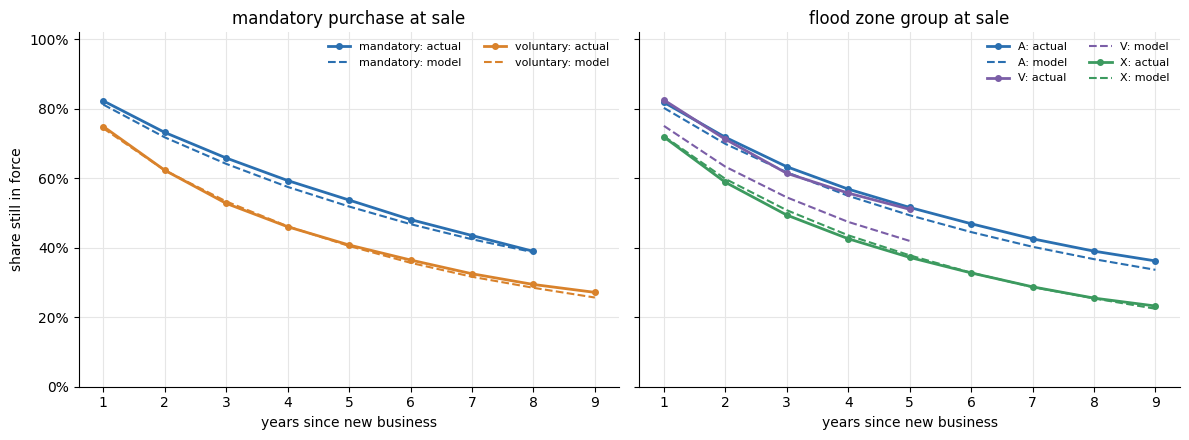

,segment_type,segment,year_k,at_risk,survival_actual,survival_model
0,mandatory purchase at sale,mandatory,1,"47,782",82.3%,81.2%
1,mandatory purchase at sale,mandatory,2,"38,280",73.2%,71.8%
2,mandatory purchase at sale,mandatory,3,"27,283",65.8%,64.1%
4,mandatory purchase at sale,mandatory,5,"11,614",53.7%,51.9%
8,mandatory purchase at sale,voluntary,1,"222,218",74.9%,74.4%
9,mandatory purchase at sale,voluntary,2,"138,158",62.3%,62.3%
10,mandatory purchase at sale,voluntary,3,"97,068",52.8%,53.3%
12,mandatory purchase at sale,voluntary,5,"49,510",40.8%,40.5%
17,flood zone group at sale,A,1,"114,212",81.8%,80.2%
18,flood zone group at sale,A,2,"76,675",71.8%,69.9%


In [32]:
# Step 2.6 Actual vs predicted retention by segment at the time of sale (all cohorts pooled)
at_sale = cohort_rows.sort_values("year_k").groupby("policy_key")[["mandatory_purchase", "zone_group"]].first()
seg_rows = cohort_rows.drop(columns=["mandatory_purchase", "zone_group"]).join(at_sale, on="policy_key")
SEG_AT_SALE = {"mandatory purchase at sale": seg_rows["mandatory_purchase"].map({1: "mandatory", 0: "voluntary"}),
               "flood zone group at sale": seg_rows["zone_group"].astype("string").fillna("(missing)")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
retention_tables = {}
for ax, (label, key) in zip(axes, SEG_AT_SALE.items()):
    for i, (g, part) in enumerate(seg_rows.groupby(key)):
        t = ev.life_table(part, CURVES, MIN_AT_RISK)
        if t.empty:
            continue
        retention_tables[(label, g)] = t
        color = ev.MODEL_COLORS[i % len(ev.MODEL_COLORS)]
        ax.plot(t.index, t["survival_actual"], color=color, linewidth=2, marker="o", markersize=4, label=f"{g}: actual")
        ax.plot(t.index, t["survival_model"], color=color, linewidth=1.5, linestyle="--", label=f"{g}: model")
    ax.set(title=label, xlabel="years since new business", ylim=(0, 1.02))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.legend(frameon=False, fontsize=8, ncol=2)
    ev.style_axes(ax)
axes[0].set_ylabel("share still in force")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_cohort_segments.png", dpi=150)
plt.show()
(pd.concat(retention_tables, names=["segment_type", "segment"]).reset_index()
   .query("year_k in [1, 2, 3, 5]")[["segment_type", "segment", "year_k", "at_risk", "survival_actual", "survival_model"]]
   .style.format({"at_risk": "{:,}", "survival_actual": "{:.1%}", "survival_model": "{:.1%}"}))

#### Our findings (Steps 2.5–2.6, final run)

Primary lapse model: the random forest (`lapse_rf`). 330,000 new policies in 11 cohorts (2014–2024), 1,065,698 policy-years.

**2.5 Retention of new business**

1. **A new flood policy has a short life.** Pooling every cohort, **23% of new policies lapse in their first year**; 65% are still in force after two years, 56% after three and **44% after five**. The hazard is highest in year 1 (23.4%), falls to 14.9% in year 2 and settles at about 8–12% from year 4. The **first renewal** is the main point of loss.
2. **Almost every lapse is a non-renewal.** In year 1, 77,336 of the 77,345 lapses were non-renewals and only 1,255 policies were cancelled during the term (a policy can carry both flags). Retention work should focus on the **renewal date**.
3. **The model follows the 2014–2020 cohorts closely**: within about **±2–3 points** in each of the first five years (e.g. 2017 cohort after year 5: 41.9% actual, 43.3% predicted). Pooled, the model is slightly pessimistic, and the gap grows with age (−1.2 points after year 1, −2.7 after year 5), because of the recent cohorts. The segment rule fits the pooled curve almost exactly but misses single cohorts by much more (2015 cohort: +6 to +8 points every year).
4. **Recent customers stay longer than the model expects.** For the **2021–2024 cohorts**, actual retention is above the prediction, and the gap widens each year:
   - 2022 cohort: 79.5% actual vs 74.8% predicted after year 1, 70.5% vs 61.1% after year 2, **63.6% vs 50.3% after year 3**;
   - 2023 cohort: 78.7% vs 74.8% after year 1, 68.5% vs 61.2% after year 2.

   These years follow **Risk Rating 2.0** (April 2022): the model reads the new prices as higher lapse risk, but fewer policyholders left.

**2.6 Retention by segment at sale**

5. **Mandatory purchase keeps policies in force:** 55.3% are still in force after five years, against 42.2% of voluntary ones. The model is 1–3.5 points too pessimistic for both.
6. **Flood zone matters most.** After five years, 53.4% of zone A and 55.0% of zone V policies are still in force, against 37.6% in zone X (rarely required by a lender). The model is right for **zone X** (within 1 point) but **too pessimistic for zones A and V**: zone A 48.3% predicted vs 53.4% actual, and **zone V 40.9% vs 55.0%** (a small group: 3,985 policies).

#### 2.7 Simulated monitoring
As in Step 1.5, with the quarterly A/E rule (no rolling window, since lapse moves slowly).

/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/sr

8 quarters in 2.2 min


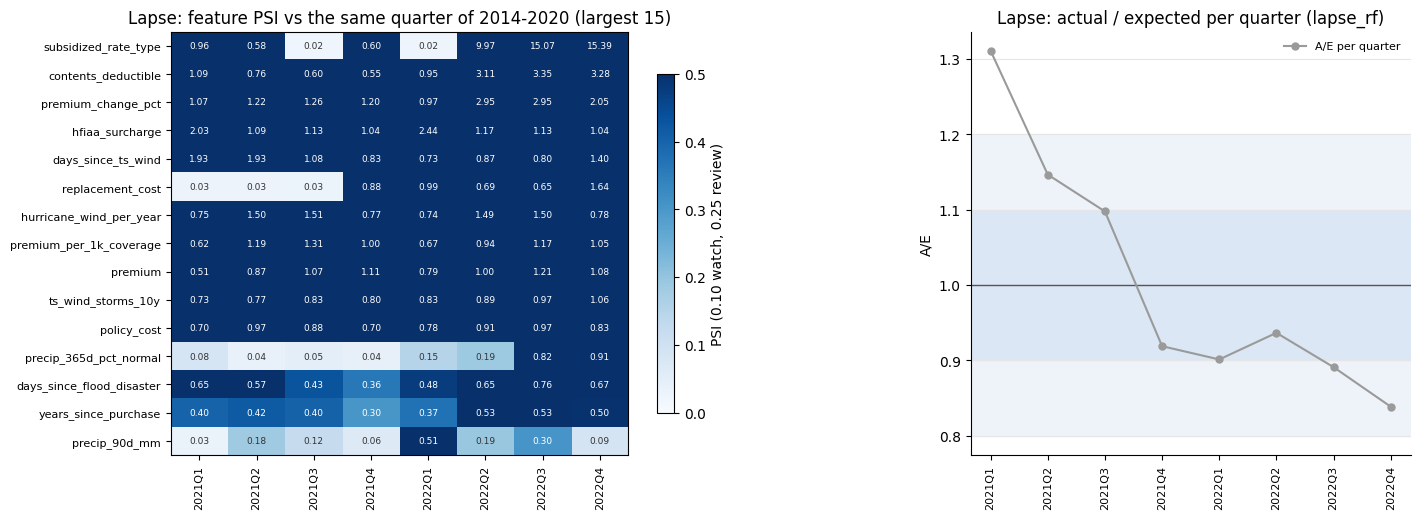

,quarter,score_psi,max_feature_psi,features_over_0.25,a_to_e,a_to_e_used,log_loss_skill,status,action
0,2021Q1,0.160,2.025,15,1.311,1.311,+8.73%,feature PSI > 0.25; score PSI watch; A/E outside 0.8-1.2,
1,2021Q2,0.151,1.929,14,1.147,1.147,+8.07%,feature PSI > 0.25; score PSI watch; A/E watch,
2,2021Q3,0.180,1.514,12,1.098,1.098,+8.75%,feature PSI > 0.25; score PSI watch,
3,2021Q4,0.183,1.195,14,0.919,0.919,+7.08%,feature PSI > 0.25; score PSI watch,
4,2022Q1,0.124,2.445,15,0.901,0.901,+6.11%,feature PSI > 0.25; score PSI watch,
5,2022Q2,0.255,9.967,16,0.937,0.937,+4.98%,feature PSI > 0.25; score PSI > 0.25,
6,2022Q3,0.295,15.073,18,0.891,0.891,+5.19%,feature PSI > 0.25; score PSI > 0.25; A/E watch,
7,2022Q4,0.193,15.387,19,0.839,0.839,+4.08%,feature PSI > 0.25; score PSI watch; A/E watch,


In [33]:
# Step 2.7 Lapse: feature PSI, score PSI and A/E per quarter, and the alert rules
t0 = time.time()
monitor_lapse, psi_lapse = ev.monitor_quarters(con, "lapse", registry["lapse"], base_rate["lapse"], KINDS, PRIMARY["lapse"],
                                                 QUARTERS, REFERENCE_ROWS, QUARTER_ROWS, seed=SEED)
alerts_lapse = ev.apply_alert_rules(monitor_lapse, rolling_quarters=None)
print(f"{len(QUARTERS)} quarters in {(time.time() - t0) / 60:.1f} min")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.45})
im = ev.plot_psi_heatmap(ax1, psi_lapse, f"Lapse: feature PSI vs the same quarter of 2014-2020 (largest 15)")
fig.colorbar(im, ax=ax1, shrink=0.8, label="PSI (0.10 watch, 0.25 review)")
x = np.arange(len(alerts_lapse))
ax2.axhspan(0.8, 1.2, color="#eef3f9", zorder=0); ax2.axhspan(0.9, 1.1, color="#dbe7f4", zorder=0)
ax2.axhline(1, color="#555555", linewidth=1)
ax2.plot(x, alerts_lapse["a_to_e"], color=ev.GREY, linewidth=1.5, marker="o", markersize=5, label="A/E per quarter")
if None:
    ax2.plot(x, alerts_lapse["a_to_e_used"], color="#2a6fb0", linewidth=2, label="A/E, 4 rolling quarters (used)")
ax2.set_xticks(x, alerts_lapse["quarter"], rotation=90, fontsize=8)
ax2.set(title=f"Lapse: actual / expected per quarter ({PRIMARY['lapse']})", ylabel="A/E")
ax2.legend(frameon=False, fontsize=8)
ev.style_axes(ax2, grid="y")
plt.savefig(REPORTS / f"fig_{OUT}_lapse_monitoring.png", dpi=150, bbox_inches="tight")
plt.show()
alerts_lapse[["quarter", "score_psi", "max_feature_psi", "features_over_0.25", "a_to_e", "a_to_e_used", "log_loss_skill",
               "status", "action"]].style.format({"score_psi": "{:.3f}", "max_feature_psi": "{:.3f}", "a_to_e": "{:.3f}",
                                                   "a_to_e_used": "{:.3f}", "log_loss_skill": "{:+.2%}"})

### Section 3. Appendix: extra checks
Two checks that tell us how much to trust the results, for both targets.

#### 3.1 Bootstrap by policy: is the gain over the benchmarks real?
We put a 95% interval on the **difference** in log loss between each other model and the primary model, on the same rows:
$$\Delta = \overline{\ell}_{\text{other}} - \overline{\ell}_{\text{primary}}, \qquad \ell_i = -\big[y_i\log p_i + (1-y_i)\log(1-p_i)\big]$$
$\Delta > 0$ means the primary model is better. Policy-years of the same policy are not independent, so we **resample policies, not rows**: each sample gives every policy a weight $w_k \sim \text{Poisson}(1)$, and $\Delta^{*} = \sum_k w_k D_k / \sum_k w_k n_k$, where $D_k$ is the sum of the differences over policy $k$'s rows and $n_k$ its number of rows. The 2.5th and 97.5th percentiles of 200 samples give the interval; if it excludes 0, the gain is real for this period.

In [34]:
# Step 3.1 Paired bootstrap of the log-loss difference, resampling policies (Poisson bootstrap)
bootstrap = pd.concat({kind: ev.bootstrap_log_loss(pred[kind], COLS[kind], f"p_{PRIMARY[kind]}", n_boot=N_BOOT, seed=SEED)
                       for kind in ev.TARGETS}, names=["target"]).reset_index(level=0)
bootstrap.style.format({"policies": "{:,}", "difference": "{:+.6f}", "ci_low": "{:+.6f}", "ci_high": "{:+.6f}"})

,target,compared_with,policies,difference,ci_low,ci_high,primary_better
0,claim,base rate,"4,103,715",-0.000701,-0.000826,-0.000560,no
1,claim,segment rate,"4,103,715",-0.002256,-0.002366,-0.002125,no
2,claim,claim_baseline_logreg,"4,103,715",-0.002419,-0.002529,-0.002272,no
3,claim,claim_lgbm,"4,103,715",+0.000695,+0.000635,+0.000743,yes
4,claim,claim_rf,"4,103,715",+0.000037,-0.000052,+0.000131,not sure
0,lapse,base rate,"3,993,058",+0.024949,+0.024798,+0.025076,yes
1,lapse,segment rate,"3,993,058",+0.014377,+0.014226,+0.014476,yes
2,lapse,lapse_baseline_logreg,"3,993,058",+0.007470,+0.007353,+0.007572,yes
3,lapse,lapse_xgb,"3,993,058",+0.002711,+0.002633,+0.002793,yes


#### 3.2 Sensitivity to policy history and linkage
FEMA's data have no policy number, so notebook 03 rebuilt each policy's history with a key. Key collisions (5.2% of policy-years) were excluded in notebook 04. The history of the policies we kept is still uncertain, so we compare the models on three kinds of history:

| History | Meaning | Why it matters |
|---|---|---|
| Continuous renewal | the previous term ended right before this one | the most reliable link |
| Returned after a gap | the key came back after a lapse | the link across the gap is less certain |
| First term on the key | no earlier term found | new business, or a missed link |

If the A/E or skill is much worse for the last two, part of the error comes from linkage, not the model. We also show how the claims of the evaluation years were matched to terms (notebook 03).

In [35]:
# Step 3.2 Claim-match quality in the evaluation years, and the models by policy history
match = con.sql(f"""
    SELECT match_status, COUNT(*) AS claims
    FROM read_parquet('{PROCESSED / 'claim_links' / '*.parquet'}')
    WHERE loss_year BETWEEN {2021 if EVAL_SPLIT == 'test' else 2023} AND {LAST_YEAR}
    GROUP BY ALL ORDER BY claims DESC""").df()
match["share"] = match["claims"] / match["claims"].sum()
display(match.style.format({"claims": "{:,}", "share": "{:.2%}"}))
history = {kind: ev.segment_table(pred[kind], COLS[kind], pred[kind]["history"]) for kind in ev.TARGETS}
for kind, t in history.items():
    print(f"{kind}: by policy history")
    display(t[["segment", "model", "rows", "events", "actual_rate", "a_to_e", "log_loss", "log_loss_skill"]].style.format(
        {"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "a_to_e": "{:.3f}", "log_loss": "{:.5f}", "log_loss_skill": "{:+.2%}"}))

,match_status,claims,share
0,matched,"97,916",91.76%
1,matched_multi,"7,791",7.30%
2,key_incomplete,465,0.44%
3,outside_term,406,0.38%
4,key_not_found,135,0.13%


claim: by policy history


,segment,model,rows,events,actual_rate,a_to_e,log_loss,log_loss_skill
0,continuous renewal,base rate,"6,475,087","74,127",1.145%,0.880,0.06265,+0.00%
1,continuous renewal,segment rate,"6,475,087","74,127",1.145%,0.863,0.06103,+2.59%
2,continuous renewal,claim_baseline_logreg,"6,475,087","74,127",1.145%,0.841,0.06082,+2.93%
3,continuous renewal,claim_lgbm,"6,475,087","74,127",1.145%,0.975,0.06420,-2.47%
4,continuous renewal,claim_rf,"6,475,087","74,127",1.145%,0.760,0.06350,-1.36%
5,continuous renewal,claim_xgb,"6,475,087","74,127",1.145%,0.983,0.06335,-1.11%
6,first term on the key,base rate,"764,467","9,114",1.192%,0.916,0.06471,+0.00%
7,first term on the key,segment rate,"764,467","9,114",1.192%,1.015,0.06375,+1.48%
8,first term on the key,claim_baseline_logreg,"764,467","9,114",1.192%,0.905,0.06400,+1.09%
9,first term on the key,claim_lgbm,"764,467","9,114",1.192%,0.984,0.06501,-0.47%


lapse: by policy history


,segment,model,rows,events,actual_rate,a_to_e,log_loss,log_loss_skill
0,continuous renewal,base rate,"6,321,185","700,507",11.082%,0.801,0.35161,+0.00%
1,continuous renewal,segment rate,"6,321,185","700,507",11.082%,0.885,0.34200,+2.73%
2,continuous renewal,lapse_baseline_logreg,"6,321,185","700,507",11.082%,1.081,0.33510,+4.70%
3,continuous renewal,lapse_rf,"6,321,185","700,507",11.082%,1.018,0.33011,+6.11%
4,continuous renewal,lapse_xgb,"6,321,185","700,507",11.082%,1.124,0.33298,+5.30%
5,first term on the key,base rate,"749,383","142,285",18.987%,1.372,0.49617,+0.00%
6,first term on the key,segment rate,"749,383","142,285",18.987%,0.912,0.47534,+4.20%
7,first term on the key,lapse_baseline_logreg,"749,383","142,285",18.987%,0.778,0.47553,+4.16%
8,first term on the key,lapse_rf,"749,383","142,285",18.987%,0.903,0.44643,+10.02%
9,first term on the key,lapse_xgb,"749,383","142,285",18.987%,0.874,0.44923,+9.46%


### Section 4. Conclusions and save

#### 4.1 Our findings (final run: validation, OOT2 = policy-years 2023 – Aug 2024)

Primary models: XGBoost for claims (`claim_xgb`), the random forest for lapse (`lapse_rf`), both chosen on the test years before the holdout was opened. A/E = actual ÷ expected (above 1 = the model predicts too few).

**Claim model**

1. **Probability check (Step 1.1):** on 2023–24 the **random forest has the best log loss** (skill **+5.8%**), ahead of the segment rule (+3.2%), the logistic regression (+3.0%) and LightGBM (+1.1%). **XGBoost, the primary model, is worse than the base rate (−1.8%)**, and the bootstrap confirms it is worse than every other model and benchmark. XGBoost ranks claims well (08a), but its scores **should not be used as probabilities**.
2. **Calibration (Step 1.2):** the logistic regression and the random forest are close on average (A/E 0.91 and 0.92) with a slope of about 1 (0.97). XGBoost and LightGBM predict too few claims (A/E 1.43 and 1.17) and are over-confident (slope 0.48 and 0.54).
3. **Claims follow storms the models can't see (Steps 1.3, 1.4):** policy-years hit by **hurricane-force wind during the term** claimed at **9.8%**, against 0.6% with no storm wind, while the models predicted about 1–2% for both (A/E 5.5–12.4 for the hurricane group, 0.35–0.56 for the calm group). This drives the **year-to-year swings**: every model over-predicts **2023** (A/E 0.58–0.90: 33,302 claims against about 57,000 expected by the logistic regression and random forest) and under-predicts **2024** (A/E 1.37–2.20: 56,214 against about 41,000), when Helene and Milton hit (Sept–Oct 2024). The same pattern runs through earlier years: the logistic regression's A/E ranges from 0.53 (2014) to 1.85 (2017).
4. **Monitoring (Step 1.5):** the primary model's quarterly A/E moves from **0.49–0.65 in 2023 Q1–Q3 to 1.9–2.7 in 2023 Q4 – 2024 Q3**; the rules call for recalibration (2023 Q3, 2024 Q2) and retraining (2024 Q3). This reflects storms more than a broken model, but expected claims need a **storm or catastrophe overlay**.

**Lapse model**

5. **Probability check (Step 2.1):** the **random forest has the best log loss** (skill +3.6%), ahead of XGBoost (+3.1%), the segment rule (+2.0%) and the logistic regression (+1.7%). The bootstrap shows the gain is real against every model, though small against XGBoost (0.0018).
6. **Calibration (Step 2.2): every model over-predicts lapse.** The random forest expects 731,822 lapses against **578,846 actual** (A/E 0.79); the logistic regression 0.84 and XGBoost 0.87. The lapse rate fell from 13.8% (train) to 10.3% (validation), and the models still carry the old level. The random forest's slope (0.80) is closer to 1 than the logistic regression's (0.53).
7. **Segments and history (Steps 2.3, 3.2):** the over-prediction is broad (continuous renewals: A/E 0.77). First-term policies lapse at 20.1%, and the random forest is closest on them (A/E 0.86). The 725 policies that returned after a gap are badly over-predicted (A/E 0.37–0.45), but they are too few to matter.
8. **Stability and monitoring (Steps 2.4, 2.7):** the random forest's A/E stays between 0.90 and 1.05 in the training years; it is 1.12 in 2021, 0.89 in 2022 and **0.78–0.81 in 2023–24**, and the quarterly A/E stays below 0.8 for most of 2023–24 (recalibration alerts in 2023 Q4 and 2024 Q1). The **price features shift sharply from 2022 Q2**: `subsidized_rate_type` (PSI 9–15), `premium_change_pct` (about 3), `premium` and `policy_cost` (about 1). This matches **Risk Rating 2.0**: the link between price and lapse learned on 2014–2020 no longer fully holds.
9. **Cohort survival (Steps 2.5–2.6):** the model follows the 2014–2020 cohorts within about ±2–3 points, but the 2021–2024 cohorts stay longer than predicted (2022 cohort after three years: 63.6% vs 50.3%), and it is too pessimistic for zones A and V.

**Recommendations**

10. **Lapse:** use the **random forest**. Before production, **recalibrate** it on recent years (e.g. isotonic or Platt on 2021–2023), which fixes expected lapses and premium at risk without changing the list; flag **the riskiest 20% of each year's renewals** rather than a fixed 2014–2020 cut-off; then **refit on 2014–2023** so the model learns the post-Risk Rating 2.0 behaviour.
11. **Claims:** for **ranking** (review lists), a tree model; for **probabilities** (expected claims), the **random forest or the logistic regression**, not XGBoost. Either way, expected claims need a **storm overlay**, because storms during the term drive most of the year-to-year change.
12. **Monitoring:** keep the quarterly checks of Steps 1.5 and 2.7. Both models already trigger their recalibration or retraining rules in 2023–24.

#### 4.2 Save the results
Every table goes to `reports/` with the prefix `eval_test_` (dry run) or `eval_valid_` (final run), next to the charts.

In [36]:
# Step 4.2 Save the tables of 08b
for kind in ev.TARGETS:
    g = globals()
    g[f"prob_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_probability.csv", index=False)
    g[f"calib_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_calibration_summary.csv", index=False)
    pd.concat(g[f"deciles_{kind}"], names=["model", "decile"]).to_csv(REPORTS / f"{OUT}_{kind}_calibration_deciles.csv")
    g[f"expected_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_expected_vs_actual.csv")
    pd.concat(g[f"seg_{kind}"], names=["segment_type"]).to_csv(REPORTS / f"{OUT}_{kind}_by_segment.csv")
    g[f"stability_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_stability_by_year.csv", index=False)
    g[f"alerts_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_monitoring.csv", index=False)
    g[f"psi_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_feature_psi.csv")
    history[kind].to_csv(REPORTS / f"{OUT}_{kind}_by_history.csv", index=False)
cohort_tables.to_csv(REPORTS / f"{OUT}_lapse_cohort_life_tables.csv", index=False)
cohort_check.to_csv(REPORTS / f"{OUT}_lapse_cohort_check.csv", index=False)
bootstrap.to_csv(REPORTS / f"{OUT}_bootstrap.csv", index=False)
print(f"saved {OUT}_* tables and charts to {REPORTS}")

saved eval_test_* tables and charts to /Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/reports


#### 4.3 Excel workbook
We collect this run's tables and charts into one workbook in `reports/`: `08b Evaluation Additional Analysis Results (test run).xlsx` or `... (validation run).xlsx`. It has a Contents tab, one tab per table and two chart tabs, with the same values as the CSV files.

Close the workbook in Excel before running this cell; a run overwrites the workbook of the same split.

In [ ]:
# Step 4.3 Collect the tables and charts of this run into one Excel workbook
from src.workbooks import write_08b_workbook

try:
    book = write_08b_workbook(REPORTS, EVAL_SPLIT)
    print(f"saved {book.name} to {REPORTS}")
except PermissionError:
    print("The workbook is open in Excel: close it and run this cell again.")